<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%207/Latihan_Praktikum_7__Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7.12 Implementasi Python — Evaluasi Model (Breast Cancer)


## Praktikum 7.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score, classification_report)

## Praktikum 7.2 Import Dataset

In [2]:
import os
FILE = "beast_cancer.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()      # pilih file beast_cancer.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

df = pd.read_csv(FILE)
print("Ukuran data awal:", df.shape)

# Bersihkan: 'id' tidak informatif, 'Unnamed: 32' kolom kosong
df = df.drop(columns=["id", "Unnamed: 32"])

# Target: M (Malignant/ganas) = 1 sebagai kelas positif, B (Benign/jinak) = 0
y = (df["diagnosis"] == "M").astype(int).values
X = df.drop(columns="diagnosis").values
print("Ukuran data bersih:", X.shape, "| distribusi [jinak, ganas]:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Train:", np.bincount(y_train), "| Test:", np.bincount(y_test))

Ukuran data awal: (569, 33)
Ukuran data bersih: (569, 30) | distribusi [jinak, ganas]: [357 212]
Train: [250 148] | Test: [107  64]


## Praktikum 7.3 Preprocessing dan Training Model

In [3]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

## Praktikum 7.4 Evaluasi

In [4]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-Score :", round(f1_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=["Jinak (0)", "Ganas (1)"]))

# Stratified k-Fold Cross-Validation untuk perbandingan model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_cv = cross_val_score(model, X, y, cv=skf, scoring="f1")
print("F1-Score tiap fold:", np.round(skor_cv, 3))
print("Rata-rata F1-Score:", round(skor_cv.mean(), 3), "+/-", round(skor_cv.std(), 3))

Confusion Matrix:
 [[106   1]
 [  4  60]]
Precision: 0.984
Recall   : 0.938
F1-Score : 0.96
              precision    recall  f1-score   support

   Jinak (0)       0.96      0.99      0.98       107
   Ganas (1)       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

F1-Score tiap fold: [0.966 0.925 0.95  0.988 0.988]
Rata-rata F1-Score: 0.963 +/- 0.024


## Praktikum 7.5 Visualisasi

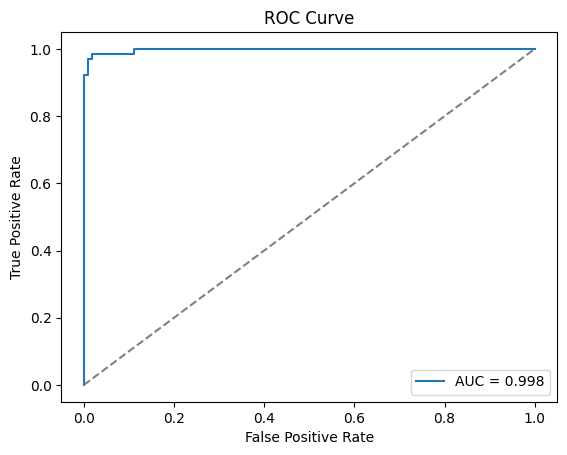

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], '--', color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()

### 7.12.1 Interpretasi

- **AUC = 0,998** (mendekati 1): model memisahkan tumor ganas dan jinak dengan sangat baik pada berbagai threshold.
- Pada test set (171 pasien): hanya 1 jinak salah diprediksi ganas (FP) dan 4 ganas terlewat (FN). Precision 0,984, recall 0,938, F1 0,960.
- **F1 CV 5-fold = 0,963 ± 0,024**: rata-rata tinggi dan simpangan baku kecil, artinya performa stabil dan tidak bergantung pada satu pembagian data tertentu, sehingga estimasi ini dapat diandalkan.
- Konteks medis: yang paling berbahaya adalah **FN** (kanker tidak terdeteksi), sehingga *recall* kelas ganas patut diperhatikan lebih dari akurasi.

---
## 7.13 Latihan Praktikum

### Praktikum 1: Laporan Evaluasi Lengkap — Logistic Regression vs Decision Tree

Melatih kedua model, membuat Confusion Matrix, menghitung Precision/Recall/F1, serta ROC curve dan PR curve kedua model dalam satu gambar.

In [6]:
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
}
hasil, proba = [], {}
for nama, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba[nama] = m.predict_proba(X_test)[:, 1]
    fpr_, tpr_, _ = roc_curve(y_test, proba[nama])
    hasil.append({"Model": nama,
                  "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC-AUC": auc(fpr_, tpr_),
                  "Average Precision (PR-AUC)": average_precision_score(y_test, proba[nama])})
    print(f"=== {nama} ===")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["Jinak (0)", "Ganas (1)"], digits=3))

display(pd.DataFrame(hasil).set_index("Model").round(3))

=== Logistic Regression ===
Confusion Matrix:
 [[106   1]
 [  4  60]]
              precision    recall  f1-score   support

   Jinak (0)      0.964     0.991     0.977       107
   Ganas (1)      0.984     0.938     0.960        64

    accuracy                          0.971       171
   macro avg      0.974     0.964     0.968       171
weighted avg      0.971     0.971     0.971       171

=== Decision Tree ===
Confusion Matrix:
 [[105   2]
 [ 14  50]]
              precision    recall  f1-score   support

   Jinak (0)      0.882     0.981     0.929       107
   Ganas (1)      0.962     0.781     0.862        64

    accuracy                          0.906       171
   macro avg      0.922     0.881     0.896       171
weighted avg      0.912     0.906     0.904       171



,Precision,Recall,F1,ROC-AUC,Average Precision (PR-AUC)
Model,,,,,
Logistic Regression,0.984,0.938,0.960,0.998,0.996
Decision Tree,0.962,0.781,0.862,0.922,0.890


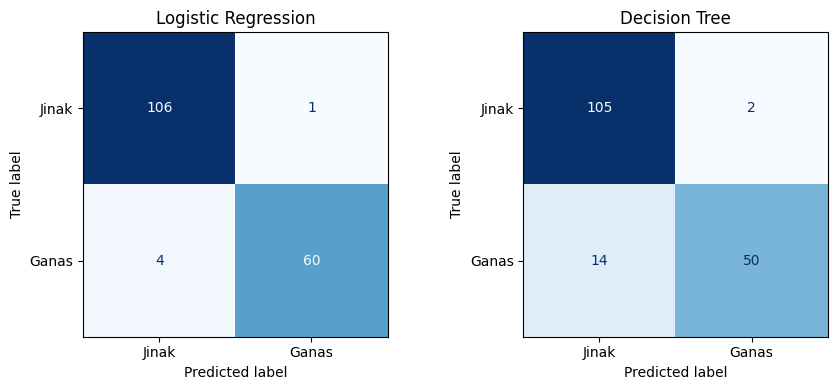

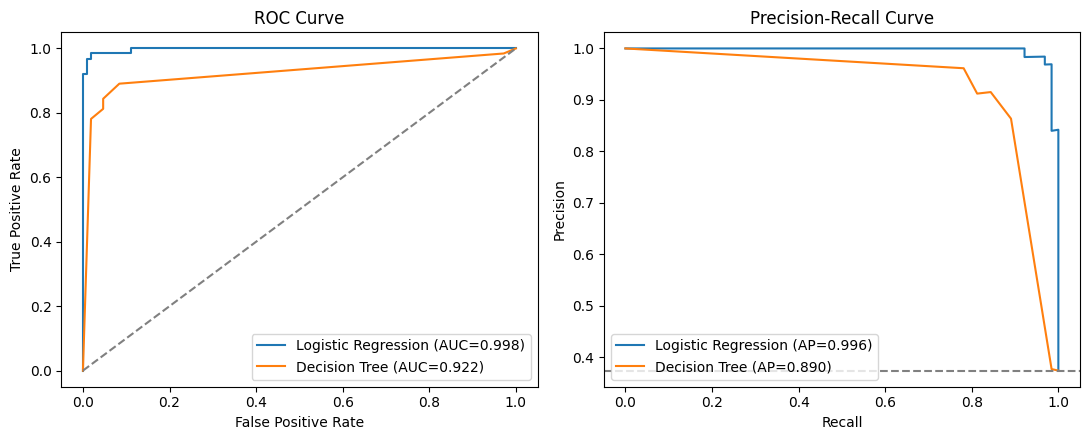

In [7]:
# Confusion Matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (nama, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax,
        display_labels=["Jinak", "Ganas"], colorbar=False, cmap="Blues")
    ax.set_title(nama)
plt.tight_layout(); plt.show()

# ROC curve & PR curve kedua model dalam satu gambar
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
for nama in models:
    f, t, _ = roc_curve(y_test, proba[nama])
    a1.plot(f, t, label=f"{nama} (AUC={auc(f, t):.3f})")
    p, r, _ = precision_recall_curve(y_test, proba[nama])
    a2.plot(r, p, label=f"{nama} (AP={average_precision_score(y_test, proba[nama]):.3f})")
a1.plot([0, 1], [0, 1], '--', color="gray")
a1.set_xlabel("False Positive Rate"); a1.set_ylabel("True Positive Rate")
a1.set_title("ROC Curve"); a1.legend(loc="lower right")
a2.axhline(y_test.mean(), ls='--', color="gray")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision")
a2.set_title("Precision-Recall Curve"); a2.legend(loc="lower left")
plt.tight_layout(); plt.show()

#### Kesimpulan Praktikum 1

| Model | FP | FN | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 1 | 4 | 0,984 | 0,938 | 0,960 | 0,998 |
| Decision Tree (depth 5) | 2 | 14 | 0,962 | 0,781 | 0,862 | 0,922 |

- **Logistic Regression lebih baik di semua metrik.** Kurva ROC-nya hampir menempel di sudut kiri atas dan kurva PR-nya berada di atas Decision Tree pada hampir seluruh rentang recall.
- Selisih terbesar ada pada **recall**: Decision Tree melewatkan 14 dari 64 tumor ganas (21,9%), sedangkan Logistic Regression hanya 4 (6,3%). Pada kasus kanker, FN inilah yang paling merugikan.
- Decision Tree menghasilkan probabilitas yang kasar (nilai daun pohon), sehingga kurva ROC/PR-nya berbentuk bertangga dan AUC-nya lebih rendah.
- **Rekomendasi:** Logistic Regression. Test set hanya 171 sampel, jadi angka ini diperkuat dengan cross-validation pada Praktikum 2.

### Praktikum 2: Perbandingan 3 Model dengan Stratified k-Fold CV (Praktikum 7.6)

Bagian (a) menjalankan kode buku apa adanya (tanpa scaling). Bagian (b) menjalankan model yang sama dengan scaling untuk Logistic Regression dan KNN.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
import warnings

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("(a) Kode buku, tanpa scaling")
model_list = {"Logistic Regression": LogisticRegression(),
              "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
              "KNN": KNeighborsClassifier(n_neighbors=5)}
ringkas_a = {}
for nama, model in model_list.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # sembunyikan ConvergenceWarning LR
        skor = cross_val_score(model, X, y, cv=skf, scoring="f1")
    ringkas_a[nama] = (skor.mean(), skor.std())
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")

print("\n(b) Dengan scaling (Pipeline)")
model_list_s = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
                "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))}
ringkas_b, skor_b = {}, {}
for nama, model in model_list_s.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1")
    skor_b[nama] = skor
    ringkas_b[nama] = (skor.mean(), skor.std())
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})  | per fold: {np.round(skor, 3)}")
# Tuliskan kesimpulan model mana yang paling baik dan paling stabil.

(a) Kode buku, tanpa scaling
Logistic Regression: F1 rata-rata = 0.928 (+/- 0.029)
Decision Tree: F1 rata-rata = 0.899 (+/- 0.038)
KNN: F1 rata-rata = 0.910 (+/- 0.029)

(b) Dengan scaling (Pipeline)
Logistic Regression: F1 rata-rata = 0.963 (+/- 0.024)  | per fold: [0.966 0.925 0.95  0.988 0.988]
Decision Tree: F1 rata-rata = 0.899 (+/- 0.038)  | per fold: [0.92  0.827 0.902 0.909 0.938]
KNN: F1 rata-rata = 0.949 (+/- 0.026)  | per fold: [0.976 0.927 0.914 0.977 0.95 ]


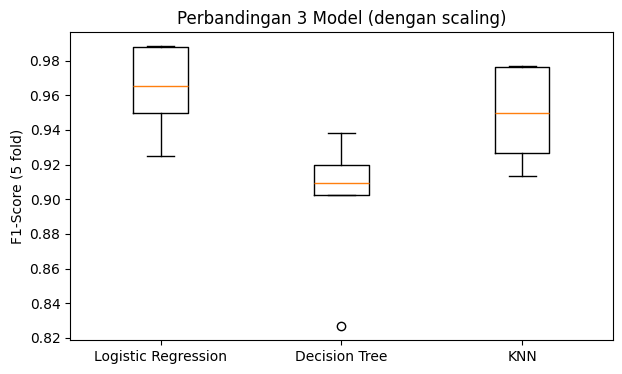

,Tanpa scaling (buku),Dengan scaling
Logistic Regression,0.928 ± 0.029,0.963 ± 0.024
Decision Tree,0.899 ± 0.038,0.899 ± 0.038
KNN,0.910 ± 0.029,0.949 ± 0.026


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(list(skor_b.values()))
ax.set_xticklabels(list(skor_b.keys()))
ax.set_ylabel("F1-Score (5 fold)"); ax.set_title("Perbandingan 3 Model (dengan scaling)")
plt.show()

pd.DataFrame({"Tanpa scaling (buku)": {k: f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in ringkas_a.items()},
              "Dengan scaling": {k: f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in ringkas_b.items()}})

#### Kesimpulan Praktikum 2 (F1 rata-rata ± simpangan baku, 5 fold)

| Model | Tanpa scaling (kode buku) | Dengan scaling |
|---|---|---|
| Logistic Regression | 0,925 ± 0,029 | **0,963 ± 0,024** |
| Decision Tree | 0,899 ± 0,038 | 0,899 ± 0,038 |
| KNN | 0,910 ± 0,029 | 0,949 ± 0,026 |

- **Paling baik:** Logistic Regression (F1 0,963 dengan scaling), disusul KNN (0,949), lalu Decision Tree (0,899).
- **Paling stabil:** Logistic Regression juga memiliki simpangan baku terkecil (0,024), hampir sama dengan KNN (0,026). Decision Tree paling tidak stabil (0,038), karena pohon sensitif terhadap perubahan data latih (variance tinggi).
- **Pengaruh scaling:** Logistic Regression naik 0,925 → 0,963 dan KNN naik 0,910 → 0,949 setelah scaling; Decision Tree tidak terpengaruh karena hanya memakai ambang per fitur. Maka perbandingan yang adil harus memakai scaling bagi model berbasis jarak/gradien.
- **Catatan:** selisih Logistic Regression dan KNN (0,014) masih lebih kecil dari simpangan baku, jadi keduanya praktis sebanding. Yang jelas tertinggal adalah Decision Tree. Hasil ini konsisten dengan Praktikum 1 (Logistic Regression terbaik, Decision Tree terlemah).